# 03 · Business Feature Engineering: U.S. Amazon financial metrics
The cleaned data is a **cross-section**: one snapshot per product, with no sales, costs or dates. To predict financial performance we need
**time-based financial targets**. This notebook builds them with documented U.S. Amazon business logic and controlled approximations.

| Target | Granularity | How it's built |
|---|---|---|
| `demand_units` | month / year | Lifetime units from ratings ÷ U.S. ratings-per-order rate × lifecycle curve × U.S. seasonality × promotions |
| `units_sold` | month / year | Demand minus stock-outs |
| `demand_share_pct`, `demand_growth_mom_pct`, `demand_growth_yoy_pct` | month / year | Share of tracked category demand; growth rates |
| `avg_price` | month / year | Everyday price × price drift × promo discounts (Prime Day, BFCM, …) |
| `gross_revenue` / `net_revenue` | month / year | Units × price, less returns |
| `net_profit`, `profit_margin_pct` | month / year | Net revenue − referral − FBA − storage − COGS − PPC − returns loss − overhead |
| `roi_cum_pct`, `roi_unit_pct` | month / year | Cumulative profit ÷ capital invested; per-unit profit ÷ landed cost |
| `break_even_months` | product | Months from launch until cumulative cash recovers the launch investment (payback period) |

**Outputs**
- `data/reference/us_category_assumptions.csv`: every economic assumption, in one editable table
- `data/processed/product_features.csv`: one row per product (static features)
- `data/processed/monthly_panel.csv`: product × month
- `data/processed/yearly_panel.csv`: product × calendar year
- `data/processed/product_summary.csv`: one row per product with launch-performance targets (first 12 / 24 months, payback)

> ⚠️ All financial values are **simulated approximations** grounded in public U.S. Amazon fee schedules (2025 FBA and referral fees) and industry
> benchmarks. They're realistic in scale and structure, but they aren't actual seller data. One random seed makes everything reproducible.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# One consistent, colour-blind-checked palette for every chart (fixed order: colour follows the entity)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ = sns.blend_palette(["#cde2fb", "#2a78d6", "#0d366b"], as_cmap=True)
DIV = sns.blend_palette(["#2a78d6", "#f0efec", "#e34948"], as_cmap=True)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=SERIES),
    "lines.linewidth": 2, "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
usd = mtick.StrMethodFormatter("${x:,.0f}")
import matplotlib.dates as mdates
def fmt_dates(ax):
    loc = mdates.AutoDateLocator(minticks=3, maxticks=8); ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
import re
RNG = np.random.default_rng(42)
REF = ROOT / "data/reference"; REF.mkdir(parents=True, exist_ok=True)
PROC = ROOT / "data/processed"; PROC.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ROOT / "data/interim/amazon_us_clean.csv")
print(df.shape)

(1351, 23)


## 1. U.S. category economics (assumption table)
Sources and reasoning:
- **Referral fee**: Amazon.com Seller Central schedule (Electronics / Computers / Camera 8%, Electronics accessories 15% (8% on the portion above $100), Kitchen / Home / Office / Toys 15%, Automotive 12%).
- **COGS (landed cost % of everyday price)**: typical private-label and brand sourcing ratios, including ocean freight and **U.S. import duties and Section 301 tariffs** on China-sourced electronics.
- **Return rate**: U.S. Amazon category averages (consumer electronics and audio highest, office lowest).
- **TACoS (total ad cost of sales)**: steady-state PPC spend share. Launch months spend roughly 2.5× this.
- **Ratings per order**: share of buyers who leave a star rating, *including star-only ratings* (U.S. ≈ 5–10%; written reviews alone are ~1–2%).
- **Lifecycle decay (months)**: how fast a product's demand fades (phones and audio refresh fast, kitchen goods slowly).
- **Elasticity**: own-price elasticity applied to promotional price cuts (published e-commerce ranges).

In [2]:
A = pd.DataFrame([
    # category,                         referral, cogs, return, tacos, ratings_per_order, decay_m, elasticity, price_drift_yr
    ("Cell Phones & Accessories",          0.15, 0.30, 0.080, 0.10, 0.080, 30, -1.6, -0.05),
    ("Electronics - Audio",                0.15, 0.28, 0.095, 0.12, 0.090, 30, -1.8, -0.05),
    ("Electronics - TV & Video",           0.08, 0.50, 0.070, 0.07, 0.070, 36, -1.3, -0.06),
    ("Electronics - Accessories",          0.15, 0.24, 0.060, 0.09, 0.070, 48, -1.7, -0.03),
    ("Computer Accessories & Peripherals", 0.15, 0.22, 0.060, 0.09, 0.070, 48, -1.9, -0.03),
    ("Computers & Accessories",            0.08, 0.52, 0.065, 0.07, 0.060, 36, -1.2, -0.06),
    ("Camera & Photo",                     0.08, 0.40, 0.070, 0.09, 0.060, 40, -1.4, -0.04),
    ("Kitchen & Home Appliances",          0.15, 0.28, 0.055, 0.09, 0.060, 72, -1.2,  0.03),
    ("Home & Kitchen",                     0.15, 0.24, 0.045, 0.10, 0.060, 72, -1.5,  0.03),
    ("Office Products",                    0.15, 0.26, 0.030, 0.08, 0.050, 84, -1.4,  0.03),
    ("Musical Instruments",                0.15, 0.32, 0.050, 0.09, 0.060, 60, -1.1,  0.02),
    ("Tools & Home Improvement",           0.15, 0.30, 0.045, 0.09, 0.060, 72, -1.2,  0.03),
    ("Toys & Games",                       0.15, 0.26, 0.050, 0.11, 0.060, 36, -1.6,  0.02),
    ("Health & Household",                 0.15, 0.24, 0.040, 0.11, 0.060, 60, -1.3,  0.03),
    ("Automotive",                         0.12, 0.30, 0.050, 0.09, 0.060, 60, -1.2,  0.03),
], columns=["us_category", "referral_rate", "cogs_rate", "return_rate", "tacos_rate", "ratings_per_order",
            "lifecycle_decay_m", "price_elasticity", "price_drift_yr"])
A.to_csv(REF / "us_category_assumptions.csv", index=False)
A

,us_category,referral_rate,cogs_rate,return_rate,tacos_rate,ratings_per_order,lifecycle_decay_m,price_elasticity,price_drift_yr
0,Cell Phones & Accessories,0.15,0.30,0.080,0.10,0.08,30,-1.6,-0.05
1,Electronics - Audio,0.15,0.28,0.095,0.12,0.09,30,-1.8,-0.05
2,Electronics - TV & Video,0.08,0.50,0.070,0.07,0.07,36,-1.3,-0.06
3,Electronics - Accessories,0.15,0.24,0.060,0.09,0.07,48,-1.7,-0.03
4,Computer Accessories & Peripherals,0.15,0.22,0.060,0.09,0.07,48,-1.9,-0.03
5,Computers & Accessories,0.08,0.52,0.065,0.07,0.06,36,-1.2,-0.06
6,Camera & Photo,0.08,0.40,0.070,0.09,0.06,40,-1.4,-0.04
7,Kitchen & Home Appliances,0.15,0.28,0.055,0.09,0.06,72,-1.2,0.03
8,Home & Kitchen,0.15,0.24,0.045,0.10,0.06,72,-1.5,0.03
9,Office Products,0.15,0.26,0.030,0.08,0.05,84,-1.4,0.03


## 2. Product attributes for fees: size tier, shipping weight, landed cost
FBA fees depend on **size tier and weight**, which the data doesn't include. We infer them from the category leaf and price (a heavier, pricier
appliance ships larger), then apply the 2025 U.S. FBA fulfilment fee curve (non-peak). Items under $10 get Amazon's **Low-Price FBA** rate
($0.77 off). Monthly storage is charged per cubic foot, at a higher rate in Q4.

In [3]:
leaf = (df.cat_leaf + " " + df.cat_l3.fillna("")).str.lower()
bulky = r"television|televisions|refrigerator|washingmachine|airconditioner|airfryer|microwave|ovens|waterheater|smarttelevision|\btv\b|monitors|printers|laptop|vacuum|purifier|geyser|roomheater|heaters|fans|cooler|dishwasher|watercooler|inverter"
small = r"cable|charger|adapter|case|cover|screenprotector|memory|microsd|card|stylus|pen|mouse|remote|battery|batteries|tape|stand|mount|earbud|in-ear|earphone|strap|gel|cleaning|notebook|paper|clip|bulb|usb"
df["size_tier"] = np.select(
    [leaf.str.contains(bulky) & (df.price_usd >= 120), leaf.str.contains(bulky) | (df.price_usd >= 150),
     leaf.str.contains(small) & (df.price_usd < 60)],
    ["large_bulky", "large_standard_heavy", "small_standard"], default="large_standard")

w_base = {"small_standard": 0.35, "large_standard": 1.4, "large_standard_heavy": 6.5, "large_bulky": 28.0}
cuft   = {"small_standard": 0.04, "large_standard": 0.25, "large_standard_heavy": 1.1, "large_bulky": 6.0}
df["ship_weight_lb"] = (df.size_tier.map(w_base) * RNG.lognormal(0, 0.30, len(df))
                        * np.clip((df.price_usd / df.groupby("size_tier").price_usd.transform("median")) ** 0.25, 0.6, 1.8)).round(2)
df["cubic_ft"] = (df.size_tier.map(cuft) * df.ship_weight_lb / df.size_tier.map(w_base)).round(3)

def fba_fee(tier, w):
    """Approximation of the 2025 U.S. FBA fulfilment fee (USD per unit)."""
    w = np.asarray(w, float); t = np.asarray(tier)
    small = np.where(w <= 0.25, 3.15, np.where(w <= 0.5, 3.40, np.where(w <= 0.75, 3.62, 3.92)))
    large = np.where(w <= 1, 4.75, np.where(w <= 2, 5.62, np.where(w <= 3, 6.30, 6.92 + 0.16 * np.ceil((w - 3) * 2))))
    bulky = 9.61 + 0.38 * np.maximum(w - 1, 0)
    return np.round(np.select([t == "small_standard", t == "large_bulky"], [small, bulky], large), 2)

df["fba_fee_unit"] = fba_fee(df.size_tier, df.ship_weight_lb)
# Amazon's Low-Price FBA rates: $0.77 less per unit for items priced under $10
df["fba_fee_unit"] = np.where(df.price_usd < 10, df.fba_fee_unit - 0.77, df.fba_fee_unit).round(2)
df = df.merge(A, on="us_category", how="left")
# Landed cost: category ratio × product-level sourcing efficiency (strong brands negotiate better) + inbound freight to FBA ($0.45/lb)
brand_eff = np.clip(1.06 - 0.04 * np.log1p(df.brand_listing_count), 0.85, 1.05)
df["landed_cost_unit"] = (df.price_usd * df.cogs_rate * brand_eff * RNG.normal(1, .08, len(df)).clip(.8, 1.2)
                          + 0.45 * df.ship_weight_lb).round(2)
df.groupby("size_tier")[["price_usd", "ship_weight_lb", "cubic_ft", "fba_fee_unit", "landed_cost_unit"]].median().round(2)

,price_usd,ship_weight_lb,cubic_ft,fba_fee_unit,landed_cost_unit
size_tier,,,,,
large_bulky,266.99,28.98,6.21,20.24,133.92
large_standard,29.99,1.34,0.24,5.62,8.75
large_standard_heavy,38.99,6.44,1.09,8.04,13.16
small_standard,9.99,0.36,0.04,2.85,3.10


### 2.1 Unit economics at the everyday price
This is the classic Amazon seller profitability check per unit (before ads):
`unit contribution = price − referral fee − FBA fee − landed cost`

count    1351.0
mean       26.8
std        23.2
min      -120.9
25%        16.4
50%        31.6
75%        42.2
max        62.2
Name: unit_margin_pct, dtype: float64


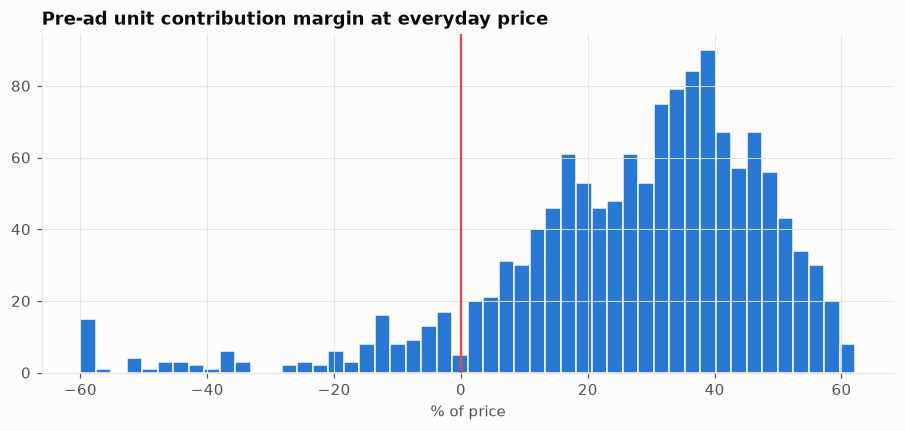

In [4]:
def referral_fee(price, rate, cat):
    # Electronics-accessory categories: 15% up to $100 and 8% above. Minimum referral fee $0.30.
    tiered = cat.isin(["Cell Phones & Accessories", "Electronics - Audio", "Electronics - Accessories", "Computer Accessories & Peripherals"])
    fee = np.where(tiered, 0.15 * np.minimum(price, 100) + 0.08 * np.maximum(price - 100, 0), price * rate)
    return np.maximum(fee, 0.30)

df["referral_fee_unit"] = referral_fee(df.price_usd, df.referral_rate, df.us_category).round(2)
df["unit_contribution"] = (df.price_usd - df.referral_fee_unit - df.fba_fee_unit - df.landed_cost_unit).round(2)
df["unit_margin_pct"] = (df.unit_contribution / df.price_usd * 100).round(2)
print(df.unit_margin_pct.describe().round(1))
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df.unit_margin_pct.clip(-60, 80), bins=50, color=SERIES[0], edgecolor="#fcfcfb")
ax.axvline(0, color=SERIES[7], lw=1.5); ax.set(title="Pre-ad unit contribution margin at everyday price", xlabel="% of price")
savefig(fig, "03_unit_margin")

Most products earn a 20–45% contribution before ads, which matches typical FBA economics. A minority of **cheap products (<$8)** are underwater:
the fixed ~$3.2 FBA fee eats the price. This is the well-known *"don't sell sub-$10 items via FBA"* rule, and the models will learn it.

## 3. Product launch dates (approximated from ASIN sequence)
Amazon assigns ASINs roughly **sequentially over time** (`B00…` ≈ pre-2015, `B07…` ≈ 2018–19, `B08…` ≈ 2020, `B09…` ≈ 2021, `B0B…` ≈ 2022).
We rank ASINs, map the rank onto a launch-date range, and add ±45 days of jitter. The timeline is shifted to a current U.S. scenario:
**observation window ends September 2026** (last full month), and the earliest launches are in 2016.

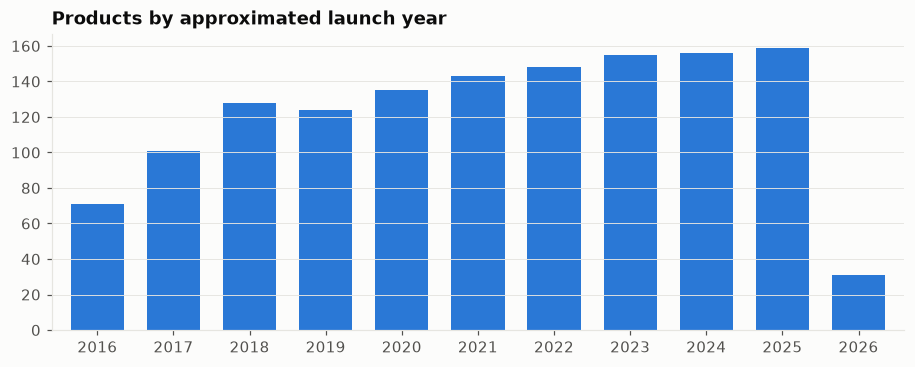

In [5]:
OBS_END = pd.Timestamp("2026-09-01")
START, LAST_LAUNCH = pd.Timestamp("2016-01-01"), pd.Timestamp("2026-03-01")
asin_rank = pd.Series(np.argsort(np.argsort(df.product_id.values)) + 1, index=df.index) / len(df)
# The scraped catalogue skews to newer ASINs, so a mild convex mapping spreads launches more evenly over time
span_days = (LAST_LAUNCH - START).days
launch = START + pd.to_timedelta((asin_rank ** 0.8) * span_days + RNG.normal(0, 45, len(df)), unit="D")
df["launch_date"] = launch.clip(START, LAST_LAUNCH).dt.to_period("M").dt.to_timestamp()
df["launch_year"] = df.launch_date.dt.year
df["launch_month"] = df.launch_date.dt.month
df["age_months_at_obs_end"] = ((OBS_END.year - df.launch_date.dt.year) * 12 + OBS_END.month - df.launch_date.dt.month)
fig, ax = plt.subplots(figsize=(10, 3.5))
df.launch_year.value_counts().sort_index().plot.bar(ax=ax, color=SERIES[0], width=.7)
ax.set(title="Products by approximated launch year", xlabel=""); ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=0)
savefig(fig, "03_launch_years")

## 4. Lifetime unit volume
Ratings are left by a small share of buyers, so **lifetime units ≈ rating_count ÷ ratings_per_order**. Products launched only a few months ago
are still early in their curve, which is fine because their small rating counts already reflect that.
We add lognormal noise (σ = 0.25) so the units-to-ratings ratio isn't perfectly deterministic. In real data it also varies with Vine programmes, review requests, etc.

In [6]:
df["lifetime_units"] = np.round(df.rating_count / df.ratings_per_order * RNG.lognormal(0, 0.25, len(df))).astype(int)
df[["rating_count", "lifetime_units"]].describe().round(0)

,rating_count,lifetime_units
count,1351.0,1351.0
mean,17619.0,252126.0
std,42120.0,601969.0
min,2.0,24.0
25%,1094.0,16735.0
50%,4736.0,74197.0
75%,15995.0,227893.0
max,426973.0,7037475.0


## 5. U.S. retail calendar: seasonality, events and macro trend
- **Base seasonality** (U.S. Amazon): soft Jan–Feb, Prime Day lift in July, **Black Friday / Cyber Monday** (Nov) and holiday peak (Dec).
- **Category overlays**: back-to-school (Aug) for computers and office; **cooling** products (fans, ACs, coolers) peak May–Aug; **heating** products peak Nov–Jan;
  gifting categories (audio, wearables, cameras) get a bigger Q4 peak.
- **Events by year**: Prime Day was 21–22 Jun 2021 and July in other years (Oct 2020 during COVID). *Prime Big Deal Days* (October) since 2022.
- **Macro index**: COVID e-commerce surge (Apr 2020 – Mar 2021), inflation softness in 2022, then ≈ +7%/yr U.S. e-commerce growth.

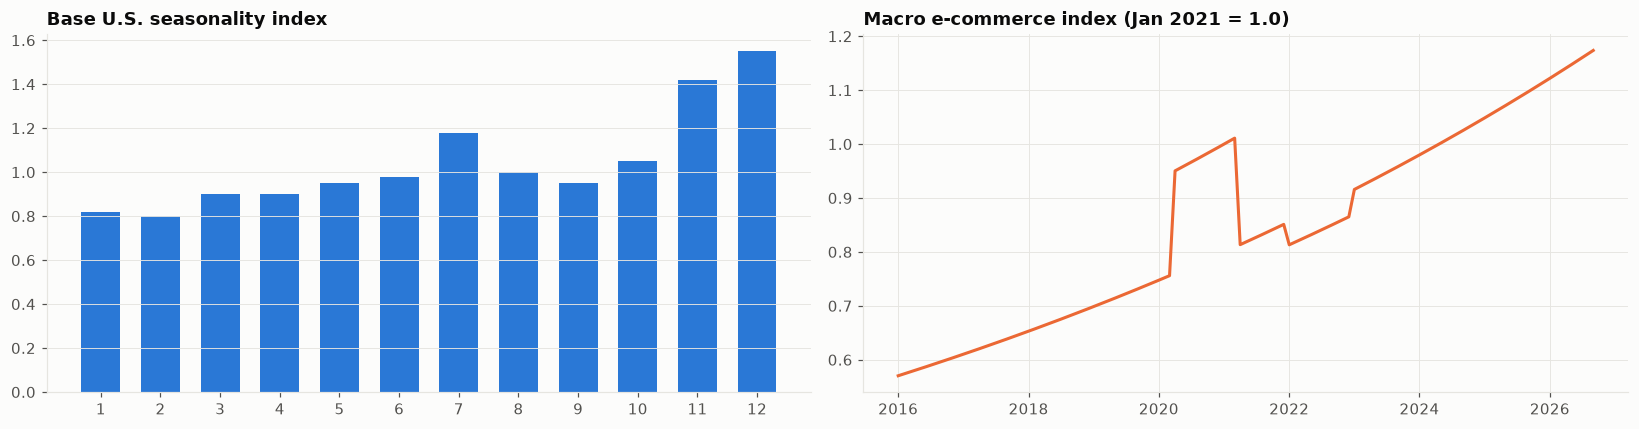

In [7]:
months = pd.date_range(START, OBS_END, freq="MS")
base_season = {1: .82, 2: .80, 3: .90, 4: .90, 5: .95, 6: .98, 7: 1.18, 8: 1.00, 9: .95, 10: 1.05, 11: 1.42, 12: 1.55}
cal = pd.DataFrame({"month": months})
cal["year"], cal["mon"] = cal.month.dt.year, cal.month.dt.month
def prime_day_month(y): return {2020: 10, 2021: 6}.get(y, 7)
cal["is_prime_day"] = (cal.mon == cal.year.map(prime_day_month)).astype(int)
cal["is_prime_big_deal_days"] = ((cal.mon == 10) & (cal.year >= 2022)).astype(int)
cal["is_bfcm"] = (cal.mon == 11).astype(int)
cal["is_holiday_peak"] = (cal.mon == 12).astype(int)
cal["is_back_to_school"] = (cal.mon == 8).astype(int)
yrs = (cal.month - pd.Timestamp("2016-01-01")).dt.days / 365.25
macro = 1.07 ** yrs
macro = np.where((cal.month >= "2020-04-01") & (cal.month <= "2021-03-01"), macro * 1.25, macro)
macro = np.where(cal.year == 2022, macro * 0.95, macro)
cal["macro_index"] = macro / macro[cal.month == "2021-01-01"][0]
cal["base_season"] = cal.mon.map(base_season)
# Prime Day isn't always in July: move the lift to whichever month holds it
cal.loc[(cal.mon == 7) & (cal.is_prime_day == 0), "base_season"] = 1.00
cal.loc[(cal.is_prime_day == 1) & (cal.mon != 7), "base_season"] *= 1.18
cal.loc[cal.is_prime_big_deal_days == 1, "base_season"] *= 1.06
cal.to_csv(REF / "us_retail_calendar.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(range(1, 13), [base_season[m] for m in range(1, 13)], color=SERIES[0], width=.65)
axes[0].set(title="Base U.S. seasonality index", xticks=range(1, 13)); axes[0].grid(axis="x", visible=False)
axes[1].plot(cal.month, cal.macro_index, color=SERIES[1])
axes[1].set(title="Macro e-commerce index (Jan 2021 = 1.0)")
fig.tight_layout(); savefig(fig, "03_calendar")

In [8]:
def season_overlay(leaf_text, us_cat):
    """Per-product 12-month multiplier vector on top of the base seasonality."""
    m = np.ones(12)
    if re.search(r"fan|cooler|airconditioner|aircooler|cooling", leaf_text): m *= np.array([.6, .7, 1.0, 1.5, 1.9, 1.9, 1.6, 1.3, .9, .6, .5, .5])
    if re.search(r"heater|geyser|waterheater|heating|blanket", leaf_text): m *= np.array([1.6, 1.3, .8, .5, .4, .4, .4, .5, .7, 1.1, 1.6, 1.8])
    if us_cat in ("Computers & Accessories", "Computer Accessories & Peripherals", "Office Products"): m[7] *= 1.20; m[8] *= 1.08
    if us_cat in ("Electronics - Audio", "Camera & Photo", "Toys & Games") or "wearable" in leaf_text or "smartwatch" in leaf_text:
        m[10] *= 1.12; m[11] *= 1.25
    return m / m.mean()

import re
leaf_txt = (df.cat_l2.fillna("") + " " + df.cat_l3.fillna("") + " " + df.cat_leaf).str.lower()
OVER = np.vstack([season_overlay(t, c) for t, c in zip(leaf_txt, df.us_category)])   # (n_products, 12)
print("Products with a cooling or heating seasonal pattern:", int((OVER.std(axis=1) > .3).sum()))

Products with a cooling or heating seasonal pattern: 158


## 6. Monthly panel simulation (product × month, launch → Sep 2026)
For each product *i* and month *t* with age *a* (months since launch):

$$\text{demand}_{i,t} \propto \underbrace{(1-e^{-(a+1)/\rho_i})}_{\text{launch ramp}} \cdot \underbrace{e^{-a/\tau_c}}_{\text{lifecycle decay}} \cdot S_{c,m} \cdot M_t \cdot \left(\tfrac{p_{i,t}}{p_i}\right)^{\varepsilon_c} \cdot Q_i \cdot \eta_{i,t}$$

- ρ = ramp speed (2–5 months). Good ratings ramp faster.
- τ = category lifecycle decay, S = seasonality, M = macro index, ε = elasticity applied to that month's price vs the everyday price.
- Q = listing-quality multiplier from rating and sentiment. η = lognormal month noise (σ = 0.18) with AR(1) persistence.
- The curve is **scaled so that Σ units_sold over the life equals lifetime_units**.
- **Stock-outs**: each month has a 5% chance of running out of stock (9% in Q4), losing 15–60% of that month's demand. So `units_sold ≤ demand_units`.

**Prices by month:** the everyday price drifts backwards in time by the category's yearly drift (electronics were *more* expensive in the past, home goods *cheaper*,
reflecting 2021–23 inflation), and promotional months cut the price.

In [9]:
n = len(df)
age_end = df.age_months_at_obs_end.values
rows = np.repeat(np.arange(n), age_end + 1)
age = np.concatenate([np.arange(a + 1) for a in age_end])
P = pd.DataFrame({"pidx": rows, "age_months": age})
P["month"] = df.launch_date.values[rows] + pd.to_timedelta(0, "D")
P["month"] = (pd.DatetimeIndex(P.month).to_period("M") + P.age_months.values).to_timestamp()
P = P.merge(cal, on="month", how="left")
print(f"Panel rows: {len(P):,}  ({n} products, {P.month.min():%Y-%m} → {P.month.max():%Y-%m})")

g = lambda col: df[col].values[P.pidx.values]

# Promotions: probability and depth by event
k = len(P); u = RNG.random(k)
promo_p = np.select([P.is_prime_day == 1, P.is_bfcm == 1, P.is_prime_big_deal_days == 1, P.is_holiday_peak == 1], [.70, .80, .50, .45], .18)
lo = np.select([P.is_prime_day == 1, P.is_bfcm == 1], [.10, .15], .05); hi = np.select([P.is_prime_day == 1, P.is_bfcm == 1], [.25, .30], .15)
P["promo_flag"] = (u < promo_p).astype(int)
P["promo_depth_pct"] = np.where(P.promo_flag == 1, RNG.uniform(lo, hi) * 100, 0).round(1)

# Everyday price drifts with age relative to Sep 2026
years_before_end = (OBS_END - P.month).dt.days / 365.25
P["everyday_price"] = g("price_usd") * (1 + g("price_drift_yr")) ** (-years_before_end)
P["avg_price"] = (P.everyday_price * (1 - P.promo_depth_pct / 100)).round(2)

# Demand shape
q = np.clip(1 + 0.6 * (g("rating") - 4.1) + 0.15 * g("review_sentiment"), 0.5, 1.6)
rho = np.clip(4.5 - 2.5 * (g("rating") - 3.6), 1.5, 5.0)
shape = (1 - np.exp(-(P.age_months + 1) / rho)) * np.exp(-P.age_months / g("lifecycle_decay_m"))
season = P.base_season.values * OVER[P.pidx.values, P.mon.values - 1]
promo_lift = (P.avg_price / P.everyday_price) ** g("price_elasticity")
eps = RNG.normal(0, .18, k)
# AR(1) noise within each product (phi = 0.5) so months aren't independent
new_prod = np.r_[True, P.pidx.values[1:] != P.pidx.values[:-1]]
ar = np.empty(k)
for i in range(k):
    ar[i] = eps[i] if new_prod[i] else 0.5 * ar[i - 1] + eps[i]
raw = shape * season * P.macro_index.values * promo_lift * q * np.exp(ar)

# Stock-outs
q4 = P.mon.isin([10, 11, 12]).values
so = RNG.random(k) < np.where(q4, .09, .05)
P["stockout_flag"] = so.astype(int)
P["lost_demand_frac"] = np.where(so, RNG.uniform(.15, .60, k), 0).round(3)
sold_raw = raw * (1 - P.lost_demand_frac)

# Scale per product so that lifetime units_sold = lifetime_units
scale = df.lifetime_units.values / pd.Series(sold_raw).groupby(P.pidx.values).sum().values
P["units_sold"] = np.round(sold_raw * scale[P.pidx.values]).astype(int)
P["demand_units"] = np.maximum(np.round(raw * scale[P.pidx.values]).astype(int), P.units_sold)
P[["units_sold", "demand_units", "avg_price"]].describe().round(1)

Panel rows: 83,316  (1351 products, 2016-01 → 2026-09)


,units_sold,demand_units,avg_price
count,83316.0,83316.0,83316.0
mean,4088.3,4191.8,53.7
std,11670.9,11948.6,107.2
min,0.0,0.0,3.3
25%,390.0,403.0,10.4
50%,1122.0,1154.0,20.4
75%,3209.0,3291.0,44.4
max,415645.0,415645.0,1424.3


## 7. Monthly P&L per product (U.S. FBA seller)
| Line | Formula |
|---|---|
| Gross revenue | units_sold × avg_price |
| Refunds | gross × return_rate (category) |
| Net revenue | gross − refunds |
| Referral fees | per unit on sold price (tiered for electronics accessories, min $0.30). Refunded except 20% admin |
| FBA fulfilment | per unit fee × units shipped |
| Storage | cubic_ft × (≈1 month of stock on hand, healthy IPI) × $0.78 Jan–Sep / $2.40 Oct–Dec |
| COGS | landed_cost × units shipped. 50% of returned units are unsellable (written off) |
| Advertising (PPC) | net revenue × TACoS × launch boost (2.5× in month 0 → 1× by month 6) |
| Overhead | 3% of net revenue (software, prep, misc.) |
| **Net profit** | net revenue − all of the above |

In [10]:
units, price = P.units_sold.values, P.avg_price.values
P["gross_revenue"] = (units * price).round(2)
rr = g("return_rate")
P["refunds"] = (P.gross_revenue * rr).round(2)
P["net_revenue"] = (P.gross_revenue - P.refunds).round(2)
ref_unit = referral_fee(pd.Series(price), pd.Series(g("referral_rate")), pd.Series(g("us_category")))
P["referral_fees"] = (units * ref_unit * (1 - rr * 0.8)).round(2)
P["fba_fees"] = (units * g("fba_fee_unit")).round(2)
storage_rate = np.where(q4, 2.40, 0.78)
P["storage_fees"] = (g("cubic_ft") * units * 1.0 * storage_rate).round(2)
# Returned units: half are resold (cost recovered), half are written off
P["cogs"] = (units * (1 - rr) * g("landed_cost_unit") + units * rr * 0.5 * g("landed_cost_unit")).round(2)
launch_boost = 1 + 1.5 * np.exp(-P.age_months / 2.5)
P["ad_spend"] = (P.net_revenue * g("tacos_rate") * launch_boost * RNG.lognormal(0, .15, k)).round(2)
P["overhead"] = (P.net_revenue * 0.03).round(2)
cost_cols = ["referral_fees", "fba_fees", "storage_fees", "cogs", "ad_spend", "overhead"]
P["total_costs"] = P[cost_cols].sum(axis=1).round(2)
P["net_profit"] = (P.net_revenue - P.total_costs).round(2)
P["profit_margin_pct"] = np.where(P.gross_revenue > 0, P.net_profit / P.gross_revenue * 100, np.nan).round(2)
P["profit_per_unit"] = np.where(units > 0, P.net_profit / units, np.nan).round(2)
P["roi_unit_pct"] = (P.profit_per_unit / g("landed_cost_unit") * 100).round(2)
P[["gross_revenue", "net_profit", "profit_margin_pct", "roi_unit_pct"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(1)

,gross_revenue,net_profit,profit_margin_pct,roi_unit_pct
count,83316.0,83316.0,83299.0,83299.0
mean,258731.0,70994.0,6.6,36.1
std,1267142.8,403947.2,27.4,78.7
min,0.0,-2332338.1,-268.8,-257.4
10%,1890.2,-2354.6,-26.4,-66.2
25%,6110.6,-87.2,-3.0,-8.1
50%,25253.5,1962.2,13.2,39.6
75%,108724.8,19022.6,24.1,85.7
90%,413678.9,95631.0,32.0,131.3
max,56190694.4,17415288.0,51.9,347.2


## 8. Investment, cumulative ROI and break-even (payback)
**Capital invested at launch** = launch fixed costs (photography, samples, brand registry and trademark, listing, compliance: $1.5k–$10k scaled by price)
\+ **initial inventory order** (the first 3 months of expected units × landed cost).

With a constant-stock replenishment policy, each month's cash flow equals net profit (sold units are reordered at landed cost). So:
- `cum_cash_position = −capital_invested + Σ net_profit`
- `roi_cum_pct = Σ net_profit ÷ capital_invested × 100`
- **`break_even_months`** = first month age at which `cum_cash_position ≥ 0`. If that hasn't happened by Sep 2026, we **project** it from the
  average profit of the last 6 months (`break_even_projected = 1`). If recent profit ≤ 0, or the projection exceeds 10 years, the product is flagged `never_breaks_even = 1` (`NaN` months).

In [11]:
first3 = P[P.age_months <= 2].groupby("pidx").units_sold.sum().reindex(range(n), fill_value=0).values
df["launch_fixed_cost"] = np.clip(1500 + 18 * df.price_usd, 1500, 10000).round(0)
df["initial_inventory_cost"] = (first3 * df.landed_cost_unit).round(2)
df["capital_invested"] = (df.launch_fixed_cost + df.initial_inventory_cost).round(2)

P["cum_net_profit"] = P.groupby("pidx").net_profit.cumsum().round(2)
P["cum_units_sold"] = P.groupby("pidx").units_sold.cumsum()
cap = g("capital_invested")
P["cum_cash_position"] = (P.cum_net_profit - cap).round(2)
P["roi_cum_pct"] = (P.cum_net_profit / cap * 100).round(2)
P["reviews_to_date"] = np.round(P.cum_units_sold * g("ratings_per_order")).astype(int)   # feature: what a seller would see

be = P[P.cum_cash_position >= 0].groupby("pidx").age_months.min()
df["break_even_months"] = be.reindex(range(n)).values
df["break_even_projected"] = 0
last6 = P[P.age_months > P.pidx.map(dict(enumerate(age_end))) - 6].groupby("pidx").net_profit.mean()
gap = -P.groupby("pidx").cum_cash_position.last()
need = df.break_even_months.isna()
proj = age_end + np.ceil(gap / last6.reindex(range(n)).values)
ok = need & (last6.reindex(range(n)).values > 0)
MAX_PAYBACK = 120   # a payback beyond 10 years isn't a meaningful investment outcome
ok = ok & (proj <= MAX_PAYBACK)
df.loc[ok, "break_even_months"] = proj[ok]
df.loc[ok, "break_even_projected"] = 1
df["never_breaks_even"] = (need & ~ok).astype(int)
print(df[["break_even_months"]].describe().round(1).T)
print("Projected:", df.break_even_projected.sum(), "| Never breaks even:", df.never_breaks_even.sum())

                   count  mean   std  min  25%  50%  75%    max
break_even_months  978.0  10.4  17.3  1.0  3.0  5.0  9.0  120.0
Projected: 58 | Never breaks even: 373


## 9. Demand in % (share and growth)
- `demand_share_pct`: product demand ÷ total tracked demand in its U.S. category that month × 100 (a market-share proxy).
- `demand_growth_mom_pct`: month-over-month change in demand units.
- `demand_growth_yoy_pct`: change vs the same month last year (removes seasonality).
- `demand_index`: demand ÷ the product's own trailing 12-month average × 100 (100 = normal month).

In [12]:
P["us_category"] = g("us_category")
cat_tot = P.groupby(["us_category", "month"]).demand_units.transform("sum")
P["demand_share_pct"] = (P.demand_units / cat_tot.replace(0, np.nan) * 100).round(4)
grp = P.groupby("pidx").demand_units
P["demand_growth_mom_pct"] = (grp.pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan) * 100).round(2)
P["demand_growth_yoy_pct"] = (grp.pct_change(12, fill_method=None).replace([np.inf, -np.inf], np.nan) * 100).round(2)
trail = grp.transform(lambda s: s.shift(1).rolling(12, min_periods=3).mean())
P["demand_index"] = (P.demand_units / trail.replace(0, np.nan) * 100).round(2)
P[["demand_share_pct", "demand_growth_mom_pct", "demand_growth_yoy_pct", "demand_index"]].describe().round(2)

,demand_share_pct,demand_growth_mom_pct,demand_growth_yoy_pct,demand_index
count,83316.00,81952.00,67254.00,79263.00
mean,2.00,8.77,-1.95,99.34
std,8.26,45.78,52.57,53.30
min,0.00,-100.00,-100.00,0.00
25%,0.10,-21.12,-31.90,66.37
50%,0.31,0.93,-12.82,85.64
75%,1.07,28.59,12.65,117.06
max,100.00,512.90,1100.00,983.66


## 10. Sanity checks against U.S. Amazon benchmarks

In [13]:
life = P.groupby("pidx").agg(rev=("gross_revenue", "sum"), prof=("net_profit", "sum"))
life_margin = life.prof / life.rev * 100
checks = pd.DataFrame({
    "metric": ["Median lifetime net margin %", "Share of products with positive lifetime profit",
               "Median monthly units (products ≥ 6 months old)", "Median break-even (months)",
               "Ad spend share of revenue %", "Q4 share of annual units % (2025)"],
    "value": [life_margin.median(), (life.prof > 0).mean() * 100,
              P[P.age_months >= 6].units_sold.median(), df.break_even_months.median(),
              P.ad_spend.sum() / P.net_revenue.sum() * 100,
              P[(P.year == 2025) & (P.mon >= 10)].units_sold.sum() / P[P.year == 2025].units_sold.sum() * 100],
    "u.s._benchmark": ["~10–25% for healthy FBA sellers", "most surviving listings profitable", "hundreds–thousands for page-1 listings",
                       "3–18 months typical", "8–15% (TACoS)", "~30–35%"],
}).round(1)
checks

,metric,value,u.s._benchmark
0,Median lifetime net margin %,13.9,~10–25% for healthy FBA sellers
1,Share of products with positive lifetime profit,72.7,most surviving listings profitable
2,Median monthly units (products ≥ 6 months old),1132.0,hundreds–thousands for page-1 listings
3,Median break-even (months),5.0,3–18 months typical
4,Ad spend share of revenue %,10.0,8–15% (TACoS)
5,Q4 share of annual units % (2025),38.1,~30–35%


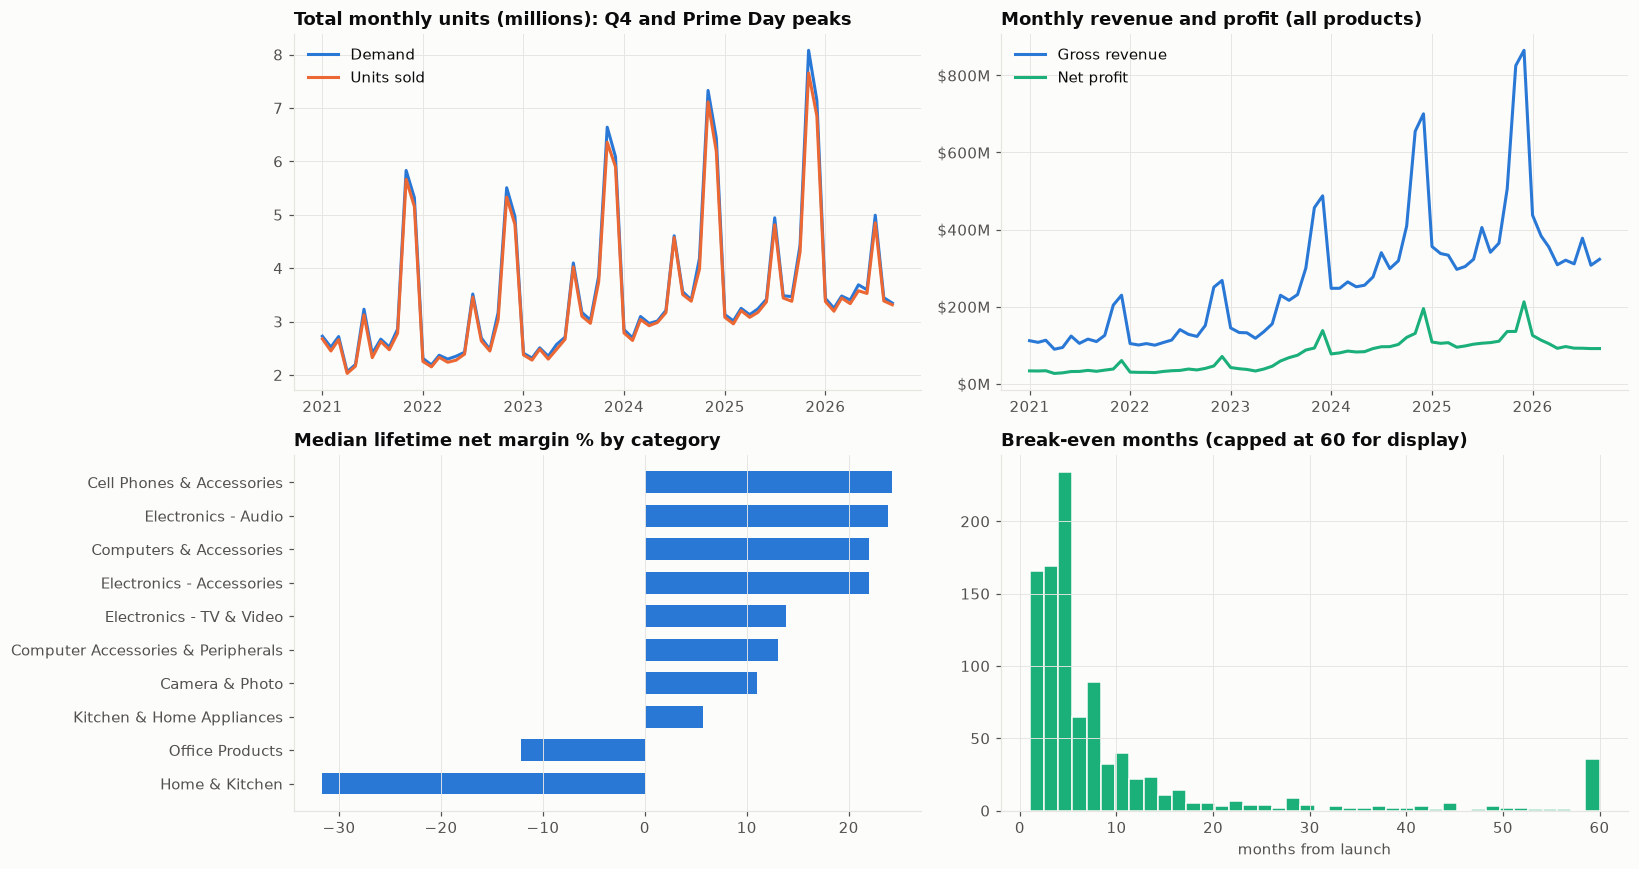

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
tot = P[P.month >= "2021-01-01"].groupby("month")[["demand_units", "units_sold", "gross_revenue", "net_profit"]].sum()
axes[0, 0].plot(tot.index, tot.demand_units / 1e6, color=SERIES[0], label="Demand")
axes[0, 0].plot(tot.index, tot.units_sold / 1e6, color=SERIES[1], label="Units sold")
axes[0, 0].set(title="Total monthly units (millions): Q4 and Prime Day peaks"); axes[0, 0].legend()
axes[0, 1].plot(tot.index, tot.gross_revenue / 1e6, color=SERIES[0], label="Gross revenue")
axes[0, 1].plot(tot.index, tot.net_profit / 1e6, color=SERIES[2], label="Net profit")
axes[0, 1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M")); axes[0, 1].set(title="Monthly revenue and profit (all products)"); axes[0, 1].legend()
fmt_dates(axes[0, 0]); fmt_dates(axes[0, 1])
mar = pd.Series(life_margin.values, index=df.us_category).groupby(level=0).median().sort_values()
mar = mar[df.us_category.value_counts().reindex(mar.index) >= 10]
axes[1, 0].barh(mar.index, mar.values, color=SERIES[0], height=.65); axes[1, 0].grid(axis="y", visible=False)
axes[1, 0].set(title="Median lifetime net margin % by category")
axes[1, 1].hist(df.break_even_months.dropna().clip(upper=60), bins=40, color=SERIES[2], edgecolor="#fcfcfb")
axes[1, 1].set(title="Break-even months (capped at 60 for display)", xlabel="months from launch")
fig.tight_layout(); savefig(fig, "03_simulation_overview")

**Reading the overview**
- Strong **Q4 (BFCM + holiday)** and **Prime Day** peaks every year, on top of e-commerce growth. These are the patterns a time-series model must learn.
- **Cheap, small Home & Kitchen and Office items lose money** after FBA fees, PPC and returns, even with Low-Price FBA rates. This is a real Amazon pattern: sub-$10 items rarely work on FBA unless sold in bundles or through FBM.
- Most profitable products pay back within **3–9 months**. A long tail takes years or never pays back. `break_even_months` is right-skewed, so model it on a log scale or as classes.

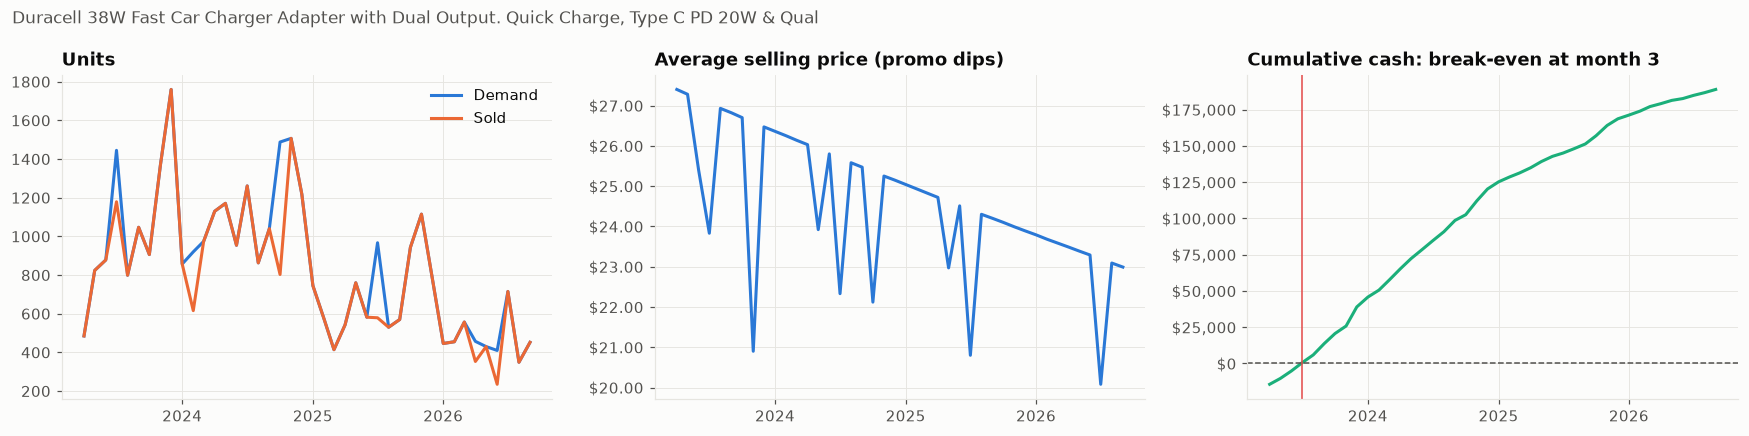

In [15]:
# One product's story: what the web-app drill-down will show
cand = df.loc[df.age_months_at_obs_end.between(30, 48) & df.break_even_months.notna() & (df.break_even_projected == 0)].sort_values("rating_count")
pid = cand.index[len(cand) // 3]
s = P[P.pidx == pid]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(s.month, s.demand_units, color=SERIES[0], label="Demand"); axes[0].plot(s.month, s.units_sold, color=SERIES[1], label="Sold")
axes[0].set(title="Units"); axes[0].legend()
axes[1].plot(s.month, s.avg_price, color=SERIES[0]); axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.2f}"))
axes[1].set(title="Average selling price (promo dips)")
axes[2].plot(s.month, s.cum_cash_position, color=SERIES[2]); axes[2].axhline(0, color=INK2, lw=1, ls="--")
axes[2].axvline(s.month.iloc[int(df.break_even_months[pid])], color=SERIES[7], lw=1)
axes[2].yaxis.set_major_formatter(usd); axes[2].set(title=f"Cumulative cash: break-even at month {int(df.break_even_months[pid])}")
for ax in axes: fmt_dates(ax)
fig.suptitle(df.product_name[pid][:90], x=.01, ha="left", fontsize=11, color=INK2)
fig.tight_layout(); savefig(fig, "03_product_example")

## 11. Assemble and save outputs

In [16]:
STATIC = ["product_id", "product_name", "brand", "us_category", "cat_l1", "cat_l2", "cat_l3", "cat_leaf", "cat_depth",
          "price_usd", "list_price_usd", "discount_pct", "orig_discount_pct", "rating", "rating_count", "review_sentiment",
          "name_len", "about_len", "n_bullets", "brand_listing_count", "is_bundle",
          "size_tier", "ship_weight_lb", "cubic_ft", "fba_fee_unit", "referral_fee_unit", "landed_cost_unit",
          "unit_contribution", "unit_margin_pct", "referral_rate", "return_rate", "tacos_rate", "price_elasticity",
          "launch_date", "launch_year", "launch_month", "age_months_at_obs_end",
          "launch_fixed_cost", "initial_inventory_cost", "capital_invested",
          "break_even_months", "break_even_projected", "never_breaks_even", "lifetime_units"]
# Listing-quality score (0-100): content richness + rating + sentiment. Replaces collinear content features.
z = lambda s: (s - s.mean()) / s.std()
lq = z(np.log1p(df.about_len)) + z(df.n_bullets.clip(upper=12)) + 1.5 * z(df.rating) + 0.5 * z(df.review_sentiment)
df["listing_quality_score"] = ((lq - lq.min()) / (lq.max() - lq.min()) * 100).round(1)
df["rating_band"] = pd.cut(df.rating, [0, 3.5, 3.8, 4.0, 4.2, 4.4, 5], labels=["<3.5", "3.5-3.8", "3.8-4.0", "4.0-4.2", "4.2-4.4", "4.4+"]).astype(str)
df["price_tier"] = pd.cut(df.price_usd, [0, 10, 25, 50, 100, 250, 1e6], labels=["<$10", "$10-25", "$25-50", "$50-100", "$100-250", "$250+"]).astype(str)
products = df[STATIC + ["listing_quality_score", "rating_band", "price_tier"]]
products.to_csv(PROC / "product_features.csv", index=False)

P["product_id"] = g("product_id")
MONTHLY = ["product_id", "month", "year", "mon", "age_months", "is_prime_day", "is_prime_big_deal_days", "is_bfcm", "is_holiday_peak",
           "is_back_to_school", "macro_index", "promo_flag", "promo_depth_pct", "stockout_flag", "lost_demand_frac", "everyday_price",
           "avg_price", "demand_units", "units_sold", "demand_share_pct", "demand_growth_mom_pct", "demand_growth_yoy_pct", "demand_index",
           "gross_revenue", "refunds", "net_revenue", "referral_fees", "fba_fees", "storage_fees", "cogs", "ad_spend", "overhead",
           "total_costs", "net_profit", "profit_margin_pct", "profit_per_unit", "roi_unit_pct",
           "cum_units_sold", "cum_net_profit", "cum_cash_position", "roi_cum_pct", "reviews_to_date"]
monthly = P[MONTHLY].rename(columns={"mon": "month_of_year"})
monthly["everyday_price"] = monthly.everyday_price.round(2)
monthly.to_csv(PROC / "monthly_panel.csv", index=False)
print("monthly_panel:", monthly.shape)

monthly_panel: (83316, 42)


In [17]:
Y = (P.groupby(["product_id", "year"])
       .agg(months_active=("month", "count"), units_sold=("units_sold", "sum"), demand_units=("demand_units", "sum"),
            gross_revenue=("gross_revenue", "sum"), net_revenue=("net_revenue", "sum"), total_costs=("total_costs", "sum"),
            net_profit=("net_profit", "sum"), ad_spend=("ad_spend", "sum"), promo_months=("promo_flag", "sum"),
            stockout_months=("stockout_flag", "sum"), age_months_end=("age_months", "max"), cum_net_profit=("cum_net_profit", "last"))
       .reset_index())
Y["avg_price"] = (Y.gross_revenue / Y.units_sold.replace(0, np.nan)).round(2)
Y["profit_margin_pct"] = (Y.net_profit / Y.gross_revenue.replace(0, np.nan) * 100).round(2)
capm = df.set_index("product_id").capital_invested
Y["roi_year_pct"] = (Y.net_profit / Y.product_id.map(capm) * 100).round(2)
Y["roi_cum_pct"] = (Y.cum_net_profit / Y.product_id.map(capm) * 100).round(2)
Y["us_category"] = Y.product_id.map(df.set_index("product_id").us_category)
Y["demand_share_pct"] = (Y.demand_units / Y.groupby(["us_category", "year"]).demand_units.transform("sum") * 100).round(4)
Y["demand_growth_yoy_pct"] = (Y.groupby("product_id").demand_units.pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan) * 100).round(2)
Y.loc[Y.groupby("product_id").months_active.shift(1) < 12, "demand_growth_yoy_pct"] = np.nan   # partial launch years aren't comparable
Y["is_partial_year"] = (Y.months_active < 12).astype(int)
Y = Y.round(2)
Y.to_csv(PROC / "yearly_panel.csv", index=False)
print("yearly_panel:", Y.shape)

yearly_panel: (7915, 22)


### Product summary: launch-performance targets
For an investor evaluating a product, the key questions are *"what will its first year look like?"* and *"when do I get my money back?"*
So the product-level targets cover the **first 12 and 24 months from launch**. They're only defined when the product is old enough
(otherwise they stay `NaN` and those products are excluded from training for that target).

In [18]:
def window(h):
    w = P[P.age_months < h].groupby("product_id")
    out = w.agg(units=("units_sold", "sum"), demand=("demand_units", "sum"), revenue=("gross_revenue", "sum"),
                profit=("net_profit", "sum"), share=("demand_share_pct", "mean"))
    out["price"] = out.revenue / out.units.replace(0, np.nan)
    out["margin_pct"] = out.profit / out.revenue.replace(0, np.nan) * 100
    out["roi_pct"] = out.profit / out.index.map(capm) * 100
    eligible = df.set_index("product_id").age_months_at_obs_end >= h - 1
    out = out.where(eligible.reindex(out.index), np.nan)
    return out.add_suffix(f"_{h}m")

S = products.set_index("product_id").join([window(12), window(24)])
S["avg_monthly_demand_12m"] = S.demand_12m / 12
S["demand_share_pct_12m"] = S.share_12m
S = S.drop(columns=["share_12m", "share_24m"]).rename(columns={"units_12m": "units_sold_12m", "units_24m": "units_sold_24m",
                                                               "demand_12m": "demand_units_12m", "demand_24m": "demand_units_24m",
                                                               "revenue_12m": "revenue_12m", "price_12m": "avg_price_12m", "price_24m": "avg_price_24m"})
last12 = P[P.month > OBS_END - pd.DateOffset(months=12)].groupby("product_id").agg(
    units_sold_ttm=("units_sold", "sum"), revenue_ttm=("gross_revenue", "sum"), net_profit_ttm=("net_profit", "sum"), demand_units_ttm=("demand_units", "sum"))
S = S.join(last12).reset_index()
numc = S.select_dtypes("number").columns; S[numc] = S[numc].round(3)
S.to_csv(PROC / "product_summary.csv", index=False)
print("product_summary:", S.shape)
S[["units_sold_12m", "revenue_12m", "profit_12m", "margin_pct_12m", "roi_pct_12m", "avg_price_12m", "break_even_months", "demand_share_pct_12m"]].describe().round(1)

product_summary: (1351, 67)


,units_sold_12m,revenue_12m,profit_12m,margin_pct_12m,roi_pct_12m,avg_price_12m,break_even_months,demand_share_pct_12m
count,1294.0,1294.0,1294.0,1294.0,1294.0,1294.0,978.0,1294.0
mean,69305.8,6261160.0,1790171.7,5.7,241.4,71.0,10.4,2.9
std,164211.3,21924929.3,7211524.3,29.1,479.1,140.6,17.3,9.4
min,19.0,104.1,-2416127.9,-186.4,-1728.6,4.1,1.0,0.0
25%,5105.8,77698.6,-571.3,-2.1,-14.8,11.0,3.0,0.1
50%,16580.5,419716.3,33136.8,12.8,200.9,22.9,5.0,0.4
75%,58942.2,2508479.3,492661.7,23.9,494.4,51.0,9.0,1.6
max,1930497.0,296353787.1,110906263.9,46.3,2121.4,1300.2,120.0,100.0


### Summary
| File | Rows | Use |
|---|---|---|
| `monthly_panel.csv` | product × month | Monthly forecasting of units, demand, price, revenue, profit, margin, ROI |
| `yearly_panel.csv` | product × year | Annual views and YoY demand growth |
| `product_summary.csv` | product | Launch evaluation: first 12/24-month metrics, break-even months |
| `product_features.csv` | product | Static features joined into every model |
| `us_category_assumptions.csv`, `us_retail_calendar.csv` | reference | Editable business assumptions for the backend |

Next: `04_model_ready_split.ipynb` builds model-ready features and the train/test split.